<a href="https://colab.research.google.com/github/ElrhAhmed/Atelier-DL/blob/main/atelier1DL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [49]:
import sys
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Make experiments reproducible
np.random.seed(42)
torch.manual_seed(42)

# Use a GPU if one is available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


In [5]:
import pandas as pd
from pathlib import Path

# Locate the file inside the downloaded dataset
prices_file = Path(dataset_path) / "prices-split-adjusted.csv"

# Read the CSV and interpret the date column as dates
prices = pd.read_csv(prices_file, parse_dates=["date"])

print("Dataset shape:", prices.shape)

# Display the first five rows
display(prices.head())

Dataset shape: (851264, 7)


,date,symbol,open,close,low,high,volume
0,2016-01-05,WLTW,123.430000,125.839996,122.309998,126.250000,2163600.0
1,2016-01-06,WLTW,125.239998,119.980003,119.940002,125.540001,2386400.0
2,2016-01-07,WLTW,116.379997,114.949997,114.930000,119.739998,2489500.0
3,2016-01-08,WLTW,115.480003,116.620003,113.500000,117.440002,2006300.0
4,2016-01-11,WLTW,117.010002,114.970001,114.089996,117.330002,1408600.0


In [6]:
# Show column names, data types, and non-missing counts
prices.info()

# Count missing values in each column
print("\nMissing values per column:")
print(prices.isna().sum())

# Count repeated observations for the same stock and date
print("\nDuplicate stock-date pairs:")
print(prices.duplicated(subset=["symbol", "date"]).sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 851264 entries, 0 to 851263
Data columns (total 7 columns):
 #   Column  Non-Null Count   Dtype         
---  ------  --------------   -----         
 0   date    851264 non-null  datetime64[ns]
 1   symbol  851264 non-null  object        
 2   open    851264 non-null  float64       
 3   close   851264 non-null  float64       
 4   low     851264 non-null  float64       
 5   high    851264 non-null  float64       
 6   volume  851264 non-null  float64       
dtypes: datetime64[ns](1), float64(5), object(1)
memory usage: 45.5+ MB

Missing values per column:
date      0
symbol    0
open      0
close     0
low       0
high      0
volume    0
dtype: int64

Duplicate stock-date pairs:
0


In [7]:
print("Earliest date:", prices["date"].min().date())
print("Latest date:", prices["date"].max().date())

print("\nNumber of stock symbols:", prices["symbol"].nunique())
print("Number of distinct trading dates:", prices["date"].nunique())

# Count daily observations for each stock
observations_per_stock = prices.groupby("symbol").size()

print("\nObservations per stock:")
display(observations_per_stock.describe())

Earliest date: 2010-01-04
Latest date: 2016-12-30

Number of stock symbols: 501
Number of distinct trading dates: 1762

Observations per stock:


,0
count,501.000000
mean,1699.129741
std,253.731238
min,126.000000
25%,1762.000000
50%,1762.000000
75%,1762.000000
max,1762.000000


In [8]:
# Summarize the numerical columns
display(prices.describe().round(2))

,date,open,close,low,high,volume
count,851264,851264.00,851264.00,851264.00,851264.00,8.512640e+05
mean,2013-07-21 02:56:29.294037760,64.99,65.01,64.34,65.64,5.415113e+06
min,2010-01-04 00:00:00,1.66,1.59,1.50,1.81,0.000000e+00
25%,2011-10-19 00:00:00,31.27,31.29,30.94,31.62,1.221500e+06
50%,2013-08-02 00:00:00,48.46,48.48,47.97,48.96,2.476250e+06
75%,2015-04-24 00:00:00,75.12,75.14,74.40,75.85,5.222500e+06
max,2016-12-30 00:00:00,1584.44,1578.13,1549.94,1600.93,8.596434e+08
std,NaN,75.20,75.20,74.46,75.91,1.249468e+07


In [9]:
# Check for prices that are zero or negative
price_columns = ["open", "close", "low", "high"]

print("Zero or negative prices per column:")
print((prices[price_columns] <= 0).sum())

# Check that open and close fall within the day's low-high range.
# A tiny tolerance avoids flagging floating-point rounding differences.
tolerance = 0.001

invalid_range = (
    (prices["low"] > prices["high"])
    | (prices["open"] < prices["low"] - tolerance)
    | (prices["open"] > prices["high"] + tolerance)
    | (prices["close"] < prices["low"] - tolerance)
    | (prices["close"] > prices["high"] + tolerance)
)

print("\nRows with inconsistent price ranges:", invalid_range.sum())
print("Rows with negative volume:", (prices["volume"] < 0).sum())

zero_volume = prices.loc[prices["volume"] == 0]

print("Rows with zero volume:", len(zero_volume))
display(zero_volume.head())

Zero or negative prices per column:
open     0
close    0
low      0
high     0
dtype: int64

Rows with inconsistent price ranges: 0
Rows with negative volume: 0
Rows with zero volume: 21


,date,symbol,open,close,low,high,volume
1270,2010-01-06,CHTR,35.000000,35.000000,35.000000,35.000000,0.0
13906,2010-02-16,CHTR,29.740000,29.740000,29.740000,29.740000,0.0
14374,2010-02-17,CHTR,29.740000,29.740000,29.740000,29.740000,0.0
15310,2010-02-19,CHTR,29.700001,29.700001,29.700001,29.700001,0.0
16246,2010-02-23,CHTR,29.700001,29.700001,29.700001,29.700001,0.0


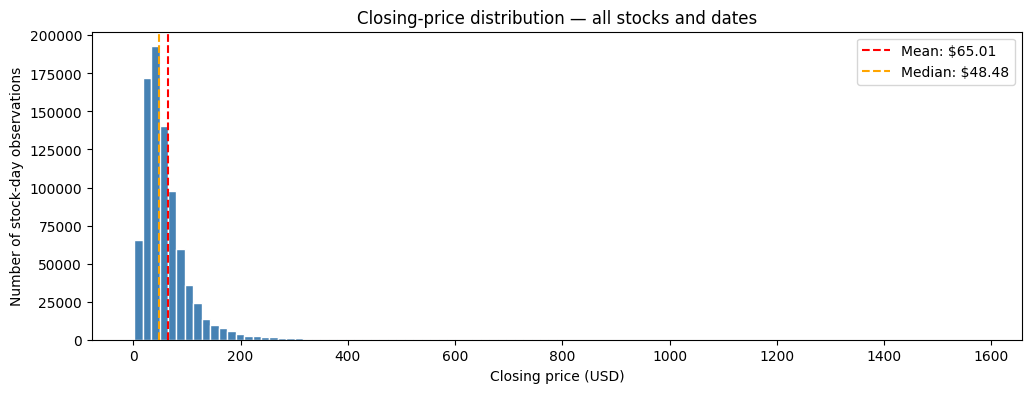

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

plt.hist(prices["close"], bins=100, color="steelblue", edgecolor="white")

plt.axvline(
    prices["close"].mean(),
    color="red",
    linestyle="--",
    label=f"Mean: ${prices['close'].mean():.2f}"
)

plt.axvline(
    prices["close"].median(),
    color="orange",
    linestyle="--",
    label=f"Median: ${prices['close'].median():.2f}"
)

plt.title("Closing-price distribution — all stocks and dates")
plt.xlabel("Closing price (USD)")
plt.ylabel("Number of stock-day observations")
plt.legend()
plt.show()

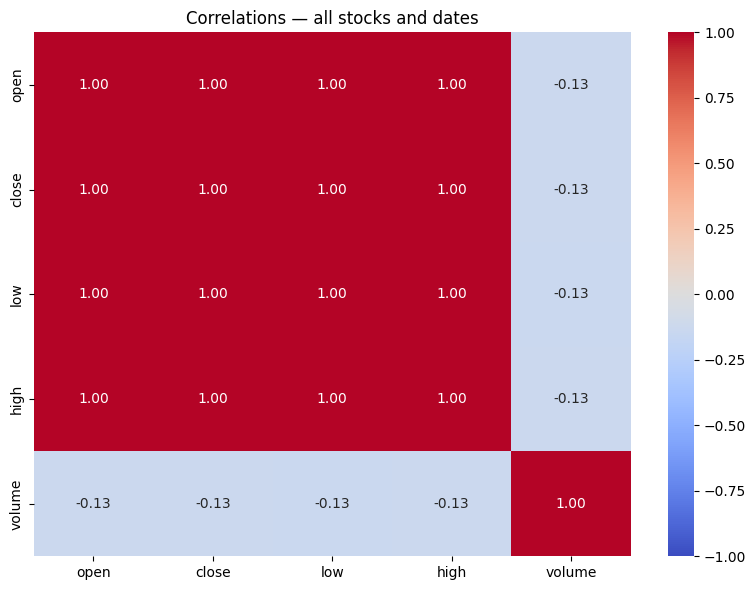

In [13]:
import seaborn as sns
import matplotlib.pyplot as plt

numerical_columns = ["open", "close", "low", "high", "volume"]

correlations = prices[numerical_columns].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlations,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Correlations — all stocks and dates")
plt.tight_layout()
plt.show()

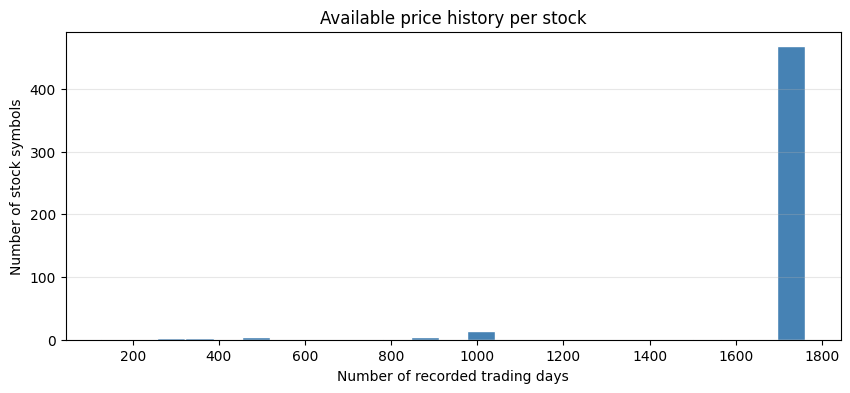

Stocks with all 1,762 recorded dates: 467
Stocks with shorter histories: 34


In [14]:
observations_per_stock = prices.groupby("symbol").size()

plt.figure(figsize=(10, 4))

plt.hist(
    observations_per_stock,
    bins=25,
    color="steelblue",
    edgecolor="white"
)

plt.title("Available price history per stock")
plt.xlabel("Number of recorded trading days")
plt.ylabel("Number of stock symbols")
plt.grid(axis="y", alpha=0.3)
plt.show()

print("Stocks with all 1,762 recorded dates:",
      (observations_per_stock == 1762).sum())

print("Stocks with shorter histories:",
      (observations_per_stock < 1762).sum())

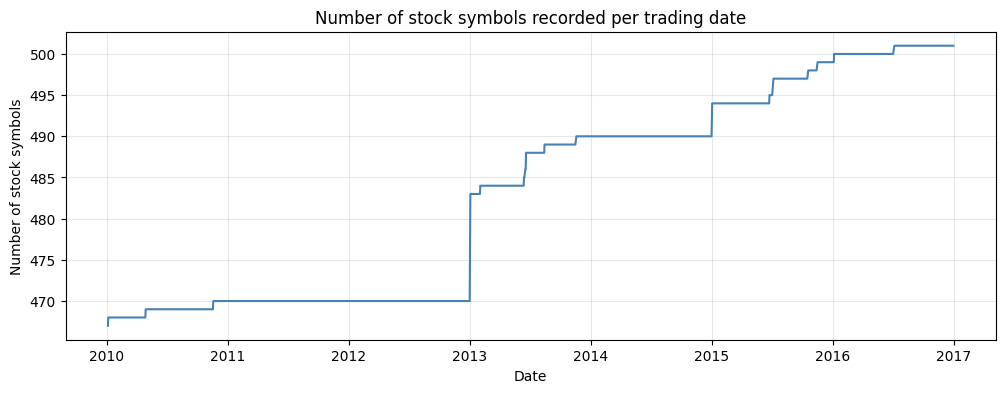

Minimum stocks on a date: 467
Maximum stocks on a date: 501


In [15]:
stocks_per_date = (
    prices.groupby("date")["symbol"]
    .nunique()
    .sort_index()
)

plt.figure(figsize=(12, 4))
plt.plot(stocks_per_date.index, stocks_per_date.values, color="steelblue")

plt.title("Number of stock symbols recorded per trading date")
plt.xlabel("Date")
plt.ylabel("Number of stock symbols")
plt.grid(alpha=0.3)
plt.show()

print("Minimum stocks on a date:", stocks_per_date.min())
print("Maximum stocks on a date:", stocks_per_date.max())

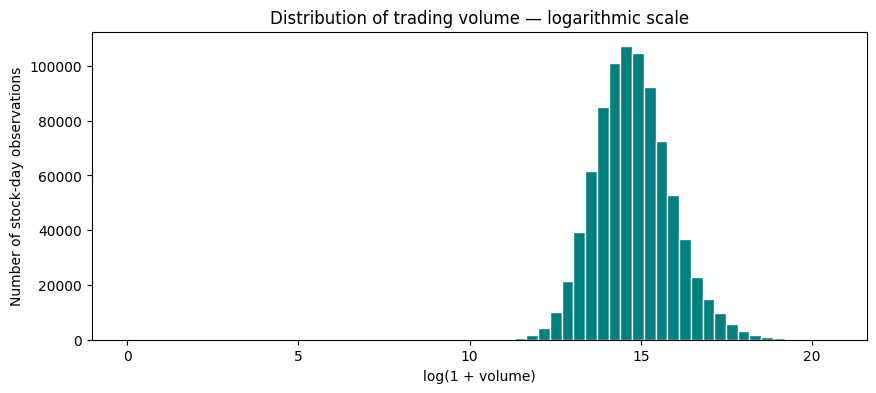

In [16]:
import numpy as np

plt.figure(figsize=(10, 4))

plt.hist(
    np.log1p(prices["volume"]),
    bins=60,
    color="teal",
    edgecolor="white"
)

plt.title("Distribution of trading volume — logarithmic scale")
plt.xlabel("log(1 + volume)")
plt.ylabel("Number of stock-day observations")
plt.show()

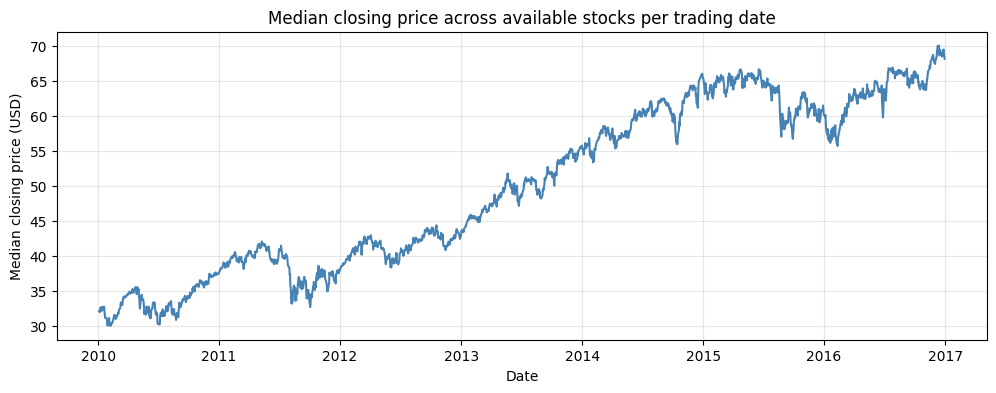

In [17]:
# Calculate the median closing price for each date
daily_median_close = (
    prices.groupby("date")["close"]
    .median()
    .sort_index()
)

plt.figure(figsize=(12, 4))

plt.plot(
    daily_median_close.index,
    daily_median_close.values,
    color="steelblue"
)

plt.title("Median closing price across available stocks per trading date")
plt.xlabel("Date")
plt.ylabel("Median closing price (USD)")
plt.grid(alpha=0.3)
plt.show()

### EDA findings

The split-adjusted price table contains 851,264 observations for
501 stock symbols between January 2010 and December 2016.

There are no missing values or duplicate stock-date pairs.
All prices are positive and respect their daily low-high ranges.
However, 21 observations have zero recorded trading volume.

Most stocks have the full 1,762-date history, while some have shorter
histories. The number of stocks recorded per date ranges from 467 to 501.

Closing prices are right-skewed: the mean ($65.01) exceeds the median
($48.48). Trading volume also has a wide range, which is easier to
visualize after a logarithmic transformation.

The four price variables are strongly correlated, while their pooled
linear correlations with volume are weakly negative.

The daily median closing price generally increases over the period,
with several declines. This summary is affected by changes in the
available stocks and should not be interpreted as an investment return.

In [18]:
# Keep each stock's observations together and ordered by date
data = (
    prices.sort_values(["symbol", "date"])
    .reset_index(drop=True)
    .copy()
)

# Attach the next recorded close and its date for each stock
data["target_close"] = (
    data.groupby("symbol")["close"].shift(-1)
)

data["target_date"] = (
    data.groupby("symbol")["date"].shift(-1)
)

# Each stock's final observation has no known next target
rows_without_target = data["target_close"].isna().sum()

data = data.dropna(
    subset=["target_close", "target_date"]
).reset_index(drop=True)

print("Rows without a next target:", rows_without_target)
print("Usable examples:", len(data))
print("Stock symbols retained:", data["symbol"].nunique())

display(
    data[
        ["symbol", "date", "close", "target_date", "target_close"]
    ].head()
)

Rows without a next target: 501
Usable examples: 850763
Stock symbols retained: 501


,symbol,date,close,target_date,target_close
0,A,2010-01-04,22.389128,2010-01-05,22.145923
1,A,2010-01-05,22.145923,2010-01-06,22.067240
2,A,2010-01-06,22.067240,2010-01-07,22.038626
3,A,2010-01-07,22.038626,2010-01-08,22.031474
4,A,2010-01-08,22.031474,2010-01-11,22.045780


In [19]:
train_data = data.loc[
    data["target_date"] < "2015-01-01"
].copy()

val_data = data.loc[
    (data["target_date"] >= "2015-01-01")
    & (data["target_date"] < "2016-01-01")
].copy()

test_data = data.loc[
    data["target_date"] >= "2016-01-01"
].copy()

for name, subset in [
    ("Training", train_data),
    ("Validation", val_data),
    ("Test", test_data)
]:
    print(
        f"{name}: {len(subset):,} examples | "
        f"Target dates: {subset['target_date'].min().date()} "
        f"to {subset['target_date'].max().date()}"
    )

# Check that every example belongs to exactly one set
assert len(train_data) + len(val_data) + len(test_data) == len(data)

Training: 599,692 examples | Target dates: 2010-01-05 to 2014-12-31
Validation: 124,948 examples | Target dates: 2015-01-02 to 2015-12-31
Test: 126,123 examples | Target dates: 2016-01-04 to 2016-12-30


In [20]:
train_symbols = set(train_data["symbol"])
val_symbols = set(val_data["symbol"])
test_symbols = set(test_data["symbol"])

print("Stocks in training:", len(train_symbols))
print("Stocks in validation:", len(val_symbols))
print("Stocks in test:", len(test_symbols))

print("\nValidation stocks absent from training:")
print(sorted(val_symbols - train_symbols))

print("\nTest stocks absent from training:")
print(sorted(test_symbols - train_symbols))

print("\nTraining stocks absent from test:")
print(sorted(train_symbols - test_symbols))

Stocks in training: 490
Stocks in validation: 499
Stocks in test: 501

Validation stocks absent from training:
['CFG', 'CSRA', 'HPE', 'KHC', 'NAVI', 'PYPL', 'QRVO', 'SYF', 'WRK']

Test stocks absent from training:
['CFG', 'CSRA', 'FTV', 'HPE', 'KHC', 'NAVI', 'PYPL', 'QRVO', 'SYF', 'WLTW', 'WRK']

Training stocks absent from test:
[]


In [21]:
# All trading dates observed anywhere in this dataset
trading_dates = pd.DatetimeIndex(
    prices["date"].unique()
).sort_values()

# Map each trading date to the following trading date
next_trading_date = pd.Series(
    trading_dates[1:],
    index=trading_dates[:-1]
)

expected_target_date = data["date"].map(next_trading_date)

# Find targets that skip an observed trading date
gap_mask = data["target_date"] != expected_target_date

print("Examples skipping a dataset trading date:", gap_mask.sum())

display(
    data.loc[
        gap_mask,
        ["symbol", "date", "target_date", "close", "target_close"]
    ].head(10)
)

Examples skipping a dataset trading date: 0


,symbol,date,target_date,close,target_close


In [22]:
from sklearn.preprocessing import StandardScaler

feature_columns = ["open", "high", "low", "close", "volume"]

# Learn scaling parameters from training data only
input_scaler = StandardScaler()

X_train = input_scaler.fit_transform(
    train_data[feature_columns]
)

# Reuse the same parameters for validation and test
X_val = input_scaler.transform(
    val_data[feature_columns]
)

X_test = input_scaler.transform(
    test_data[feature_columns]
)

print("Input shapes:")
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

print("\nScaled training means:")
print(X_train.mean(axis=0).round(4))

print("\nScaled training standard deviations:")
print(X_train.std(axis=0).round(4))

Input shapes:
Training: (599692, 5)
Validation: (124948, 5)
Test: (126123, 5)

Scaled training means:
[-0.  0. -0.  0. -0.]

Scaled training standard deviations:
[1. 1. 1. 1. 1.]


In [24]:
# Scale the next-day closing prices separately from the inputs
target_scaler = StandardScaler()

y_train = target_scaler.fit_transform(
    train_data[["target_close"]]
)

y_val = target_scaler.transform(
    val_data[["target_close"]]
)

y_test = target_scaler.transform(
    test_data[["target_close"]]
)

# Check that each input example has one target
print("Training:  ", X_train.shape, "→", y_train.shape)
print("Validation:", X_val.shape, "→", y_val.shape)
print("Test:      ", X_test.shape, "→", y_test.shape)

# Display the original dates and prices to verify the pairing
display(
    train_data[
        ["symbol", "date", "close", "target_date", "target_close"]
    ].head()
)

Training:   (599692, 5) → (599692, 1)
Validation: (124948, 5) → (124948, 1)
Test:       (126123, 5) → (126123, 1)


,symbol,date,close,target_date,target_close
0,A,2010-01-04,22.389128,2010-01-05,22.145923
1,A,2010-01-05,22.145923,2010-01-06,22.067240
2,A,2010-01-06,22.067240,2010-01-07,22.038626
3,A,2010-01-07,22.038626,2010-01-08,22.031474
4,A,2010-01-08,22.031474,2010-01-11,22.045780


In [25]:
import torch

# Convert inputs to PyTorch tensors
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
X_val_tensor = torch.tensor(X_val, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test, dtype=torch.float32)

# Convert targets to PyTorch tensors
y_train_tensor = torch.tensor(y_train, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.float32)

print("Training input shape:", X_train_tensor.shape)
print("Training target shape:", y_train_tensor.shape)
print("Number type:", X_train_tensor.dtype)

print("\nFirst standardized input:")
print(X_train_tensor[0])

print("\nIts standardized target:")
print(y_train_tensor[0])

Training input shape: torch.Size([599692, 5])
Training target shape: torch.Size([599692, 1])
Number type: torch.float32

First standardized input:
tensor([-0.5662, -0.5673, -0.5655, -0.5676, -0.1413])

Its standardized target:
tensor([-0.5717])


In [26]:
from torch.utils.data import TensorDataset, DataLoader

# Pair each input row with its target
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

batch_size = 1024

# Reproducible shuffling of training examples
generator = torch.Generator().manual_seed(42)

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    generator=generator
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))
print("Maximum examples per batch:", batch_size)

Training batches: 586
Validation batches: 123
Test batches: 124
Maximum examples per batch: 1024


In [27]:
from torch import nn

torch.manual_seed(42)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = nn.Sequential(
    nn.Linear(5, 64),
    nn.ReLU(),

    nn.Linear(64, 32),
    nn.ReLU(),

    nn.Linear(32, 1)
).to(device)

print("Device:", device)
print(model)

parameter_count = sum(p.numel() for p in model.parameters())
print("\nTrainable parameters:", parameter_count)

# Check that the network produces one output per example
model.eval()

with torch.no_grad():
    sample_predictions = model(X_train_tensor[:3].to(device))

print("\nOutput shape for 3 examples:", sample_predictions.shape)
print(sample_predictions.cpu())

Device: cuda
Sequential(
  (0): Linear(in_features=5, out_features=64, bias=True)
  (1): ReLU()
  (2): Linear(in_features=64, out_features=32, bias=True)
  (3): ReLU()
  (4): Linear(in_features=32, out_features=1, bias=True)
)

Trainable parameters: 2497

Output shape for 3 examples: torch.Size([3, 1])
tensor([[0.0613],
        [0.0601],
        [0.0633]])


In [28]:
# Measure the difference between predicted and actual targets
criterion = nn.MSELoss()

# Update the network's weights during training
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Loss function:", criterion)
print("Optimizer:", type(optimizer).__name__)
print("Learning rate:", optimizer.param_groups[0]["lr"])

Loss function: MSELoss()
Optimizer: Adam
Learning rate: 0.001


In [29]:
import copy

epochs = 10
history = {"train_loss": [], "val_loss": []}

best_val_loss = float("inf")
best_model_state = None

for epoch in range(epochs):

    # 1. Learn from the training batches
    model.train()
    train_loss_sum = 0.0

    for inputs, targets in train_loader:
        inputs = inputs.to(device)
        targets = targets.to(device)

        optimizer.zero_grad()

        predictions = model(inputs)
        loss = criterion(predictions, targets)

        loss.backward()
        optimizer.step()

        train_loss_sum += loss.item() * inputs.size(0)

    train_loss = train_loss_sum / len(train_dataset)

    # 2. Evaluate on validation data without updating weights
    model.eval()
    val_loss_sum = 0.0

    with torch.no_grad():
        for inputs, targets in val_loader:
            inputs = inputs.to(device)
            targets = targets.to(device)

            predictions = model(inputs)
            loss = criterion(predictions, targets)

            val_loss_sum += loss.item() * inputs.size(0)

    val_loss = val_loss_sum / len(val_dataset)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    # Keep the weights with the lowest validation loss
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_model_state = copy.deepcopy(model.state_dict())

    print(
        f"Epoch {epoch + 1:02d}/{epochs} | "
        f"Train MSE: {train_loss:.6f} | "
        f"Validation MSE: {val_loss:.6f}"
    )

# Restore the best model found during this run
model.load_state_dict(best_model_state)

print(f"\nBest validation MSE: {best_val_loss:.6f}")

Epoch 01/10 | Train MSE: 0.032960 | Validation MSE: 0.001627
Epoch 02/10 | Train MSE: 0.000688 | Validation MSE: 0.001456
Epoch 03/10 | Train MSE: 0.000666 | Validation MSE: 0.001487
Epoch 04/10 | Train MSE: 0.000662 | Validation MSE: 0.001455
Epoch 05/10 | Train MSE: 0.000653 | Validation MSE: 0.001383
Epoch 06/10 | Train MSE: 0.000652 | Validation MSE: 0.001343
Epoch 07/10 | Train MSE: 0.000646 | Validation MSE: 0.001879
Epoch 08/10 | Train MSE: 0.000639 | Validation MSE: 0.001329
Epoch 09/10 | Train MSE: 0.000634 | Validation MSE: 0.001281
Epoch 10/10 | Train MSE: 0.000623 | Validation MSE: 0.001256

Best validation MSE: 0.001256


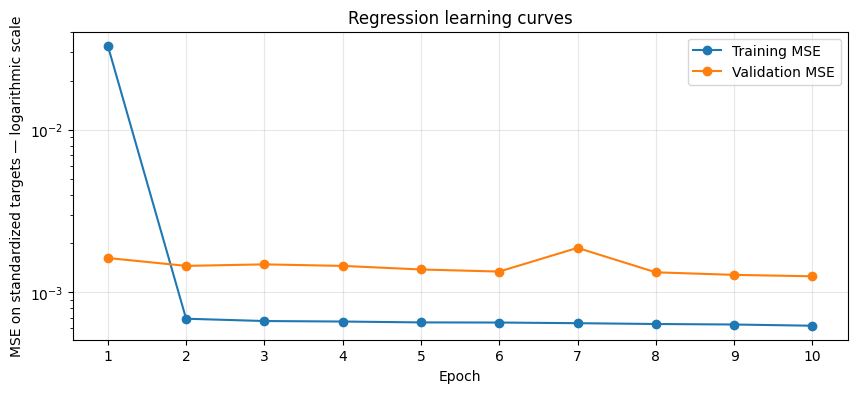

In [30]:
epoch_numbers = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(10, 4))

plt.plot(
    epoch_numbers,
    history["train_loss"],
    marker="o",
    label="Training MSE"
)

plt.plot(
    epoch_numbers,
    history["val_loss"],
    marker="o",
    label="Validation MSE"
)

# Log scale makes both the initial drop and smaller changes visible
plt.yscale("log")

plt.title("Regression learning curves")
plt.xlabel("Epoch")
plt.ylabel("MSE on standardized targets — logarithmic scale")
plt.xticks(list(epoch_numbers))
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [31]:
# Predict validation targets using the trained network
model.eval()
prediction_batches = []

with torch.no_grad():
    for inputs, _ in val_loader:
        predictions = model(inputs.to(device))
        prediction_batches.append(predictions.cpu())

scaled_predictions = torch.cat(prediction_batches).numpy()

# Convert network predictions back to dollars
model_predictions = target_scaler.inverse_transform(
    scaled_predictions
).ravel()

# Actual next-day prices and baseline predictions, also in dollars
actual_prices = val_data["target_close"].to_numpy()
baseline_predictions = val_data["close"].to_numpy()

def calculate_errors(actual, predicted):
    errors = predicted - actual

    return {
        "MAE ($)": np.mean(np.abs(errors)),
        "RMSE ($)": np.sqrt(np.mean(errors ** 2))
    }

results = pd.DataFrame({
    "Baseline: next close = current close": calculate_errors(
        actual_prices, baseline_predictions
    ),
    "PyTorch MLP": calculate_errors(
        actual_prices, model_predictions
    )
}).T

display(results.round(4))

,MAE ($),RMSE ($)
Baseline: next close = current close,0.9608,2.1010
PyTorch MLP,0.9897,2.1542


In [33]:
%pip install -q skorch

import skorch
import sklearn

from skorch import NeuralNetRegressor
from sklearn.model_selection import GridSearchCV, PredefinedSplit



In [34]:
from torch import nn

class RegressionMLP(nn.Module):

    def __init__(self, input_size=5, hidden_sizes=(64, 32)):
        super().__init__()

        layers = []
        previous_size = input_size

        # Add the requested hidden layers
        for hidden_size in hidden_sizes:
            layers.append(nn.Linear(previous_size, hidden_size))
            layers.append(nn.ReLU())
            previous_size = hidden_size

        # One output: standardized next-day closing price
        layers.append(nn.Linear(previous_size, 1))

        self.network = nn.Sequential(*layers)

    def forward(self, X):
        return self.network(X)


# Check the architecture without training
example_model = RegressionMLP(hidden_sizes=(64, 32))

print(example_model)
print(
    "\nTrainable parameters:",
    sum(p.numel() for p in example_model.parameters())
)

RegressionMLP(
  (network): Sequential(
    (0): Linear(in_features=5, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=1, bias=True)
  )
)

Trainable parameters: 2497


In [35]:
net = NeuralNetRegressor(
    module=RegressionMLP,
    module__hidden_sizes=(64, 32),

    criterion=nn.MSELoss,
    optimizer=torch.optim.Adam,
    lr=0.001,

    max_epochs=10,
    batch_size=1024,
    iterator_train__shuffle=True,

    train_split=None,
    device=str(device),
    verbose=0
)

print("Model wrapper:", type(net).__name__)
print("Hidden layers:", net.get_params()["module__hidden_sizes"])
print("Learning rate:", net.get_params()["lr"])
print("Epochs:", net.get_params()["max_epochs"])
print("Device:", net.get_params()["device"])

Model wrapper: NeuralNetRegressor
Hidden layers: (64, 32)
Learning rate: 0.001
Epochs: 10
Device: cuda


In [36]:
import numpy as np

# Combine the existing standardized arrays
X_search = np.concatenate(
    [X_train, X_val], axis=0
).astype(np.float32)

y_search = np.concatenate(
    [y_train, y_val], axis=0
).astype(np.float32)

# -1 = always training; 0 = validation for this split
split_labels = np.concatenate([
    np.full(len(X_train), -1, dtype=int),
    np.zeros(len(X_val), dtype=int)
])

chronological_split = PredefinedSplit(test_fold=split_labels)

# Check the actual split GridSearch will use
train_indices, val_indices = next(
    chronological_split.split()
)

print("Combined input shape:", X_search.shape)
print("Combined target shape:", y_search.shape)
print("Training examples:", len(train_indices))
print("Validation examples:", len(val_indices))

assert len(train_indices) == len(X_train)
assert len(val_indices) == len(X_val)
assert train_indices.max() < val_indices.min()

print("\nChronological split verified.")

Combined input shape: (724640, 5)
Combined target shape: (724640, 1)
Training examples: 599692
Validation examples: 124948

Chronological split verified.


In [37]:
from sklearn.model_selection import ParameterGrid

param_grid = {
    "lr": [0.001, 0.0001],
    "optimizer": [torch.optim.Adam, torch.optim.SGD],
    "max_epochs": [10, 20],
    "module__hidden_sizes": [(64, 32), (128, 64)]
}

number_of_combinations = len(list(ParameterGrid(param_grid)))

print("Learning rates:", param_grid["lr"])
print("Optimizers:", [opt.__name__ for opt in param_grid["optimizer"]])
print("Epoch counts:", param_grid["max_epochs"])
print("Hidden-layer sizes:", param_grid["module__hidden_sizes"])
print("\nTotal combinations:", number_of_combinations)

Learning rates: [0.001, 0.0001]
Optimizers: ['Adam', 'SGD']
Epoch counts: [10, 20]
Hidden-layer sizes: [(64, 32), (128, 64)]

Total combinations: 16


In [38]:
# Reproducible starting point for this search
np.random.seed(42)
torch.manual_seed(42)

search = GridSearchCV(
    estimator=net,
    param_grid=param_grid,
    scoring="neg_mean_absolute_error",
    cv=chronological_split,
    refit=False,
    n_jobs=1,
    verbose=2,
    error_score="raise"
)

search.fit(X_search, y_search)

# Convert the best validation MAE from standardized units to dollars
best_mae_scaled = -search.best_score_
best_mae_dollars = best_mae_scaled * target_scaler.scale_[0]

print("\nBest hyperparameters:")
for name, value in search.best_params_.items():
    print(f"{name}: {value}")

print(f"\nBest validation MAE: ${best_mae_dollars:.4f}")

Fitting 1 folds for each of 16 candidates, totalling 16 fits
[CV] END lr=0.001, max_epochs=10, module__hidden_sizes=(64, 32), optimizer=<class 'torch.optim.adam.Adam'>; total time=  52.3s
[CV] END lr=0.001, max_epochs=10, module__hidden_sizes=(64, 32), optimizer=<class 'torch.optim.sgd.SGD'>; total time=  47.0s
[CV] END lr=0.001, max_epochs=10, module__hidden_sizes=(128, 64), optimizer=<class 'torch.optim.adam.Adam'>; total time=  48.0s
[CV] END lr=0.001, max_epochs=10, module__hidden_sizes=(128, 64), optimizer=<class 'torch.optim.sgd.SGD'>; total time=  46.7s
[CV] END lr=0.001, max_epochs=20, module__hidden_sizes=(64, 32), optimizer=<class 'torch.optim.adam.Adam'>; total time= 1.7min
[CV] END lr=0.001, max_epochs=20, module__hidden_sizes=(64, 32), optimizer=<class 'torch.optim.sgd.SGD'>; total time= 1.6min
[CV] END lr=0.001, max_epochs=20, module__hidden_sizes=(128, 64), optimizer=<class 'torch.optim.adam.Adam'>; total time= 1.6min
[CV] END lr=0.001, max_epochs=20, module__hidden_size

In [39]:
grid_results = pd.DataFrame(search.cv_results_)

grid_summary = pd.DataFrame({
    "Learning rate": grid_results["param_lr"].astype(float),
    "Optimizer": [
        optimizer.__name__
        for optimizer in grid_results["param_optimizer"]
    ],
    "Epochs": grid_results["param_max_epochs"].astype(int),
    "Hidden layers": grid_results["param_module__hidden_sizes"],
    "Validation MAE ($)": (
        -grid_results["mean_test_score"]
        * target_scaler.scale_[0]
    )
})

grid_summary = (
    grid_summary.sort_values("Validation MAE ($)")
    .reset_index(drop=True)
)

display(grid_summary.round({"Validation MAE ($)": 4}))

,Learning rate,Optimizer,Epochs,Hidden layers,Validation MAE ($)
0,0.0010,Adam,20,"(64, 32)",0.9739
1,0.0001,Adam,20,"(64, 32)",1.0012
2,0.0001,Adam,10,"(128, 64)",1.0124
3,0.0001,Adam,10,"(64, 32)",1.0308
4,0.0010,Adam,20,"(128, 64)",1.0340
5,0.0001,Adam,20,"(128, 64)",1.0432
6,0.0010,Adam,10,"(128, 64)",1.0650
7,0.0010,Adam,10,"(64, 32)",1.1404
8,0.0010,SGD,10,"(128, 64)",1.5170
9,0.0010,SGD,20,"(128, 64)",1.6617


In [40]:
from sklearn.base import clone
from skorch.helper import predefined_split

# Start a fresh, reproducible training run
np.random.seed(42)
torch.manual_seed(42)

# Copy the wrapper and apply the winning settings
tuned_net = clone(net)
tuned_net.set_params(
    **search.best_params_,
    train_split=predefined_split(val_dataset),
    verbose=1
)

# Train using training data; monitor the existing validation set
tuned_net.fit(
    X_train.astype(np.float32),
    y_train.astype(np.float32)
)

print("\nTraining complete.")
print("Recorded epochs:", len(tuned_net.history))

  epoch    train_loss    valid_loss     dur
-------  ------------  ------------  ------
      1        0.0306        0.0018  7.8048
      2        0.0007        0.0015  5.5559
      3        0.0007        0.0014  5.7992
      4        0.0007        0.0016  5.6360
      5        0.0007        0.0014  5.7566
      6        0.0006        0.0015  5.5335
      7        0.0006        0.0017  5.8806
      8        0.0007        0.0013  5.6013
      9        0.0007        0.0018  5.8233
     10        0.0007        0.0013  5.4725
     11        0.0006        0.0013  5.7202
     12        0.0006        0.0013  5.5344
     13        0.0006        0.0017  5.6986
     14        0.0006        0.0013  5.5815
     15        0.0006        0.0016  5.7343
     16        0.0006        0.0012  5.5450
     17        0.0006        0.0012  5.7077
     18        0.0006        0.0013  5.6330
     19        0.0006        0.0014  5.7050
     20        0.0006        0.0012  5.5607

Training complete.
Recorded epo

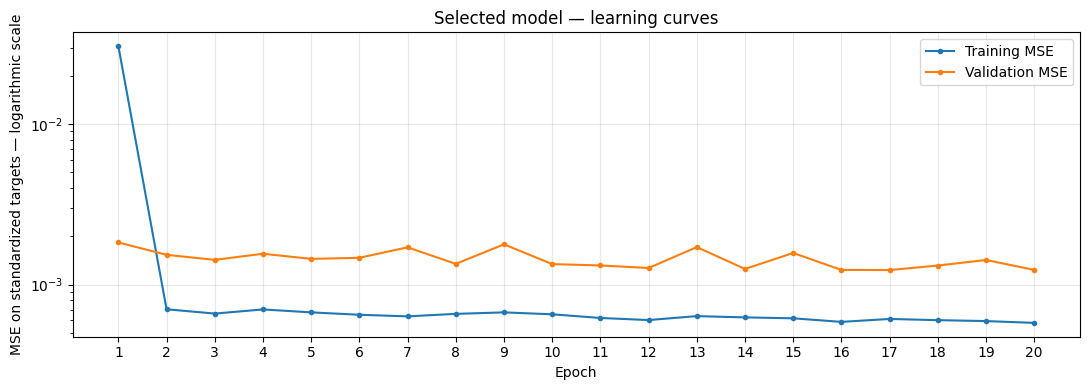

Epoch with lowest validation MSE: 17
Lowest validation MSE: 0.001234
Final validation MSE: 0.001237


In [41]:
# Extract the losses recorded by Skorch
tuned_train_loss = np.array(tuned_net.history[:, "train_loss"])
tuned_val_loss = np.array(tuned_net.history[:, "valid_loss"])

epoch_numbers = np.arange(1, len(tuned_train_loss) + 1)

plt.figure(figsize=(11, 4))

plt.plot(
    epoch_numbers, tuned_train_loss,
    label="Training MSE", marker="o", markersize=3
)

plt.plot(
    epoch_numbers, tuned_val_loss,
    label="Validation MSE", marker="o", markersize=3
)

plt.yscale("log")
plt.xlabel("Epoch")
plt.ylabel("MSE on standardized targets — logarithmic scale")
plt.title("Selected model — learning curves")
plt.xticks(epoch_numbers)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

best_epoch = tuned_val_loss.argmin() + 1

print("Epoch with lowest validation MSE:", best_epoch)
print("Lowest validation MSE:", f"{tuned_val_loss.min():.6f}")
print("Final validation MSE:", f"{tuned_val_loss[-1]:.6f}")

In [42]:
# Predict validation prices
tuned_predictions_scaled = tuned_net.predict(
    X_val.astype(np.float32)
)

# Convert predictions back to dollars
tuned_predictions = target_scaler.inverse_transform(
    tuned_predictions_scaled
).ravel()

# Keep the earlier baseline and initial-model results
comparison_results = results.rename(
    index={"PyTorch MLP": "Initial MLP"}
).copy()

tuned_errors = calculate_errors(
    val_data["target_close"].to_numpy(),
    tuned_predictions
)

comparison_results.loc["Tuned MLP"] = tuned_errors

display(comparison_results.round(4))

,MAE ($),RMSE ($)
Baseline: next close = current close,0.9608,2.1010
Initial MLP,0.9897,2.1542
Tuned MLP,0.9753,2.1378


In [43]:
class RegularizedMLP(nn.Module):

    def __init__(
        self,
        input_size=5,
        hidden_sizes=(64, 32),
        dropout=0.0
    ):
        super().__init__()

        layers = []
        previous_size = input_size

        for hidden_size in hidden_sizes:
            layers.append(nn.Linear(previous_size, hidden_size))
            layers.append(nn.ReLU())
            layers.append(nn.Dropout(p=dropout))
            previous_size = hidden_size

        layers.append(nn.Linear(previous_size, 1))

        self.network = nn.Sequential(*layers)

    def forward(self, X):
        return self.network(X)


# Inspect an example with 10% dropout
dropout_example = RegularizedMLP(dropout=0.1)

print(dropout_example)
print(
    "\nTrainable parameters:",
    sum(p.numel() for p in dropout_example.parameters())
)

RegularizedMLP(
  (network): Sequential(
    (0): Linear(in_features=5, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.1, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.1, inplace=False)
    (6): Linear(in_features=32, out_features=1, bias=True)
  )
)

Trainable parameters: 2497


In [44]:
regularization_experiments = {
    "No regularization": {
        "dropout": 0.0,
        "weight_decay": 0.0
    },
    "Dropout": {
        "dropout": 0.1,
        "weight_decay": 0.0
    },
    "Weight decay": {
        "dropout": 0.0,
        "weight_decay": 0.0001
    },
    "Dropout + weight decay": {
        "dropout": 0.1,
        "weight_decay": 0.0001
    }
}

display(
    pd.DataFrame.from_dict(
        regularization_experiments,
        orient="index"
    )
)

,dropout,weight_decay
No regularization,0.0,0.0000
Dropout,0.1,0.0000
Weight decay,0.0,0.0001
Dropout + weight decay,0.1,0.0001


In [45]:
regularized_models = {}
regularization_scores = []

for name, settings in regularization_experiments.items():

    print(f"\nTraining: {name}", flush=True)

    # Reset randomness before each experiment
    np.random.seed(42)
    torch.manual_seed(42)

    experiment_net = NeuralNetRegressor(
        module=RegularizedMLP,
        module__hidden_sizes=search.best_params_["module__hidden_sizes"],
        module__dropout=settings["dropout"],

        criterion=nn.MSELoss,
        optimizer=search.best_params_["optimizer"],
        optimizer__weight_decay=settings["weight_decay"],
        lr=search.best_params_["lr"],

        max_epochs=search.best_params_["max_epochs"],
        batch_size=1024,
        iterator_train__shuffle=True,

        train_split=predefined_split(val_dataset),
        device=str(device),
        verbose=0
    )

    experiment_net.fit(
        X_train.astype(np.float32),
        y_train.astype(np.float32)
    )

    predictions_scaled = experiment_net.predict(
        X_val.astype(np.float32)
    )

    predictions_dollars = target_scaler.inverse_transform(
        predictions_scaled
    ).ravel()

    errors = calculate_errors(
        val_data["target_close"].to_numpy(),
        predictions_dollars
    )

    regularized_models[name] = experiment_net

    regularization_scores.append({
        "Experiment": name,
        **settings,
        **errors
    })

    print(
        f"Validation MAE: ${errors['MAE ($)']:.4f} | "
        f"RMSE: ${errors['RMSE ($)']:.4f}",
        flush=True
    )

regularization_results = (
    pd.DataFrame(regularization_scores)
    .set_index("Experiment")
    .sort_values("MAE ($)")
)

display(regularization_results.round(4))


Training: No regularization
Validation MAE: $0.9753 | RMSE: $2.1378

Training: Dropout
Validation MAE: $2.3465 | RMSE: $4.7363

Training: Weight decay
Validation MAE: $1.0131 | RMSE: $2.2272

Training: Dropout + weight decay
Validation MAE: $1.1200 | RMSE: $2.3260


,dropout,weight_decay,MAE ($),RMSE ($)
Experiment,,,,
No regularization,0.0,0.0000,0.9753,2.1378
Weight decay,0.0,0.0001,1.0131,2.2272
Dropout + weight decay,0.1,0.0001,1.1200,2.3260
Dropout,0.1,0.0000,2.3465,4.7363


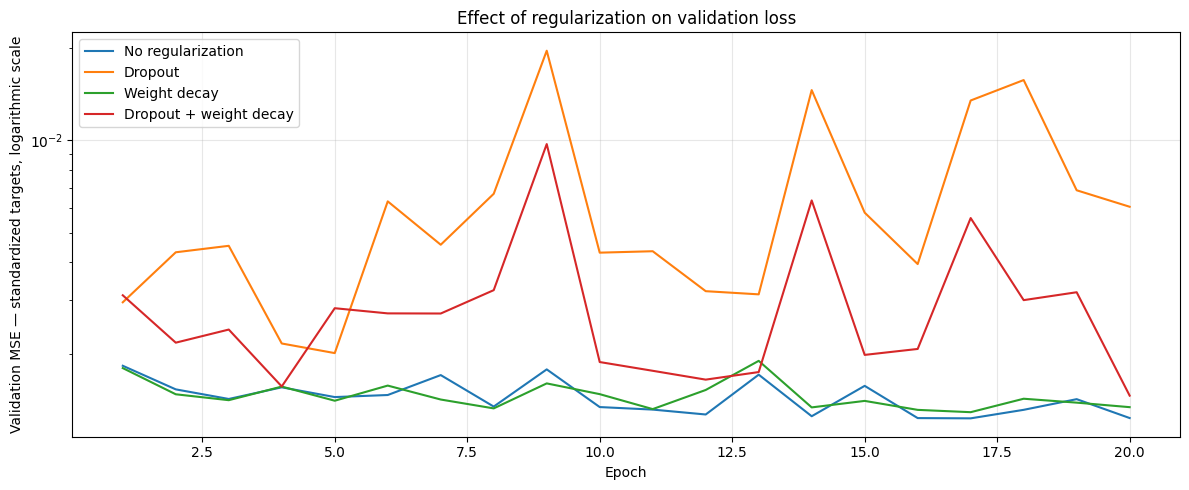

In [46]:
plt.figure(figsize=(12, 5))

for name, trained_net in regularized_models.items():
    validation_losses = np.array(
        trained_net.history[:, "valid_loss"]
    )

    plt.plot(
        range(1, len(validation_losses) + 1),
        validation_losses,
        label=name
    )

plt.yscale("log")
plt.title("Effect of regularization on validation loss")
plt.xlabel("Epoch")
plt.ylabel("Validation MSE — standardized targets, logarithmic scale")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [47]:
test_actual = test_data["target_close"].to_numpy()

test_scores = {
    "Baseline": calculate_errors(
        test_actual,
        test_data["close"].to_numpy()
    )
}

# Evaluate the original PyTorch model
model.eval()
initial_test_batches = []

with torch.no_grad():
    for inputs, _ in test_loader:
        predictions = model(inputs.to(device))
        initial_test_batches.append(predictions.cpu())

initial_test_scaled = torch.cat(initial_test_batches).numpy()

initial_test_predictions = target_scaler.inverse_transform(
    initial_test_scaled
).ravel()

test_scores["Initial MLP"] = calculate_errors(
    test_actual,
    initial_test_predictions
)

# Evaluate the tuned control and regularized variants
for name, trained_net in regularized_models.items():
    predictions_scaled = trained_net.predict(
        X_test.astype(np.float32)
    )

    predictions_dollars = target_scaler.inverse_transform(
        predictions_scaled
    ).ravel()

    label = (
        "Tuned MLP — no regularization"
        if name == "No regularization"
        else name
    )

    test_scores[label] = calculate_errors(
        test_actual,
        predictions_dollars
    )

test_results = pd.DataFrame.from_dict(
    test_scores, orient="index"
)

display(test_results.round(4))

,MAE ($),RMSE ($)
Baseline,0.9508,2.1505
Initial MLP,0.9814,2.1904
Tuned MLP — no regularization,0.9708,2.1819
Dropout,2.4454,5.0558
Weight decay,1.0072,2.2652
Dropout + weight decay,1.1088,2.3487


In [48]:
selected_net = regularized_models["No regularization"]

final_scores = {}

for name, X_values, original_data in [
    ("Training", X_train, train_data),
    ("Test", X_test, test_data)
]:
    predictions_scaled = selected_net.predict(
        X_values.astype(np.float32)
    )

    predictions_dollars = target_scaler.inverse_transform(
        predictions_scaled
    ).ravel()

    actual = original_data["target_close"].to_numpy()

    final_scores[name] = calculate_errors(
        actual, predictions_dollars
    )

final_performance = pd.DataFrame.from_dict(
    final_scores, orient="index"
)

display(final_performance.round(4))

,MAE ($),RMSE ($)
Training,0.6592,1.4078
Test,0.9708,2.1819


## Part 1 — Results and interpretation

I built a PyTorch MLP to predict each stock’s next trading-day closing price using its current-day open, high, low, close, and volume.

### Data exploration and preparation

I explored the split-adjusted price table, which contains 851,264 observations for 501 stock symbols. I found no missing values or duplicate stock–date pairs. However, I identified 21 zero-volume observations and differences in history length between stocks.

I split the prediction examples chronologically by target date: 2010–2014 for training, 2015 for validation, and 2016 for testing. I standardized inputs and targets using parameters calculated from training data only.

### Hyperparameter tuning

I used GridSearchCV to evaluate 16 hyperparameter combinations with a predefined chronological validation split. The selected configuration used:

- Two hidden layers with 64 and 32 neurons.
- ReLU activations.
- The Adam optimizer.
- A learning rate of 0.001.
- 20 training epochs.

I kept the batch size fixed at 1,024.

### Learning curves

Training loss decreased rapidly during the first epochs. Validation loss improved overall but fluctuated, without a sustained increase.

I used MSE for the learning curves and MAE/RMSE for evaluation because ordinary classification accuracy is not appropriate for continuous price predictions. I monitored validation performance during development and reserved the test set for final evaluation.

### Test results

| Method | Test MAE (USD) | Test RMSE (USD) |
| --- | ---: | ---: |
| Current-close baseline | **0.9508** | **2.1505** |
| Initial MLP | 0.9814 | 2.1904 |
| Tuned MLP without regularization | 0.9708 | 2.1819 |
| Dropout | 2.4454 | 5.0558 |
| Weight decay | 1.0072 | 2.2652 |
| Dropout + weight decay | 1.1088 | 2.3487 |

The tuned MLP achieved a training MAE of 0.6592 USD and a test MAE of 0.9708 USD. The higher test error indicates weaker performance on unseen dates, although differences between the periods also contribute to this gap.

Hyperparameter tuning improved the initial network’s performance. However, the tuned model did not outperform the baseline that predicts the next closing price as equal to the current closing price.

### Effect of regularization

I tested dropout, weight decay, and their combination. None improved validation performance at the tested settings, and their test errors were also higher than those of the model without regularization. Dropout alone produced the largest errors.

These results apply to the regularization strengths and training duration tested. They do not establish that regularization cannot help under other settings.

### Limitations

The reported metrics aggregate stocks with different price levels and history lengths. They do not imply equal performance for every stock. Some validation and test stocks were also absent from training.

### What I learned

I learned how to prepare chronological prediction targets, standardize data without using future information, train a PyTorch network, tune hyperparameters, and compare regularization techniques.

Most importantly, I learned that decreasing training loss does not guarantee a useful model: performance must also be assessed on unseen data against a simple baseline.